# Investigate Hotel Business using Data Visualization
### Understanding Booking & Cancellation Behaviour — Hotel Bookings 2017–2019

**Tool:** Jupyter Notebook (Python) &nbsp;|&nbsp; **Libraries:** Pandas, NumPy, Matplotlib, Seaborn
**Dataset:** Hotel bookings, 2017–2019 (~119K rows × 29 cols)

This notebook works through Stages 0–3 of the project brief: problem framing, data cleaning,
analysis of three business questions, and a summary of recommendations for a hotel manager.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

HOTEL_COLORS = {'City Hotel': '#2C4160', 'Resort Hotel': '#C9A24B'}
pd.set_option('display.max_columns', 40)

## Stage 0 — Problem Statement

**1. Why does understanding customer booking behaviour matter for a hotel business?**

Every booking a hotel takes is a promise of future revenue — but a cancelled booking turns that
promise into an empty room and lost income. Understanding *why* guests book, and *why* they cancel,
lets a hotel forecast occupancy more accurately, price rooms dynamically, staff the right number of
people on the right days, and design cancellation/deposit policies that protect revenue without
scaring off legitimate guests. It turns booking data from a record of the past into a tool for
decisions about the future.

**2. The three business questions, restated:**
- **Popularity:** Between the City Hotel and the Resort Hotel, which one do customers choose more often, and does that change by month?
- **Stay length:** Do guests who book longer stays cancel more or less often than guests who book short stays?
- **Lead time:** Do guests who book far in advance cancel more or less often than guests who book at the last minute?

**3. Project objective**

The main deliverable is a set of clear, labelled visualisations — backed by a cleaned dataset — that
answer the three questions above, together with concrete, evidence-based recommendations a
non-technical hotel manager could act on (e.g. seasonal staffing, cancellation policy design,
deposit rules for long-lead-time bookings).

## Stage 1 — Data Preprocessing
### 1.1 Data Overview

In [2]:
df_raw = pd.read_csv('data/hotel_bookings_data.csv')
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
print(f"Period covered: {df_raw['arrival_date_year'].min()}–{df_raw['arrival_date_year'].max()}")
df_raw.head()

Rows: 119,390   Columns: 29
Period covered: 2017–2019


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_weekdays_nights,adults,children,babies,meal,city,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status
0,Resort Hotel,0,342,2017,September,27,1,0,0,2,0.0,0,Breakfast,Kota Denpasar,Direct,Direct,0,0,0,3,No Deposit,NaN,NaN,0,Personal,0.0,0,0,Check-Out
1,Resort Hotel,0,737,2017,September,27,1,0,0,2,0.0,0,Breakfast,Kota Denpasar,Direct,Direct,0,0,0,4,No Deposit,NaN,NaN,0,Personal,0.0,0,0,Check-Out
2,Resort Hotel,0,7,2017,September,27,1,0,1,1,0.0,0,Breakfast,Kabupaten Bangka,Direct,Direct,0,0,0,0,No Deposit,NaN,NaN,0,Personal,75.0,0,0,Check-Out
3,Resort Hotel,0,13,2017,September,27,1,0,1,1,0.0,0,Breakfast,Kabupaten Bangka,Corporate,Corporate,0,0,0,0,No Deposit,304.0,NaN,0,Personal,75.0,0,0,Check-Out
4,Resort Hotel,0,14,2017,September,27,1,0,2,2,0.0,0,Breakfast,Kabupaten Bangka,Online TA,TA/TO,0,0,0,0,No Deposit,240.0,NaN,0,Personal,98.0,0,1,Check-Out


**Columns most relevant to our three business questions:**

| Column | Relevance |
|---|---|
| `hotel` | City Hotel vs Resort Hotel — the popularity question |
| `arrival_date_year/month/day` | When the stay happens — seasonality |
| `stays_in_weekend_nights`, `stays_in_weekday_nights` | Combine into total stay length |
| `lead_time` | Days between booking and arrival |
| `is_canceled` | Our target: 1 = cancelled, 0 = completed/kept |
| `adr`, `market_segment`, `deposit_type` | Support the "why" behind recommendations |

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 29 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_weekdays_nights        119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

### 1.2 Data Assessment

We assess data quality issue by issue and justify how each is handled. The same logic is
implemented in `data_cleaning.py` so the dashboard and this notebook always agree.

**1. Missing values**

In [4]:
missing = df_raw.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df_raw) * 100).round(1)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

,missing_count,missing_pct
company,112593,94.3
agent,16340,13.7
city,488,0.4
children,4,0.0


- **`company`** (94% missing) — almost every booking has no company on file. Missing here simply
  means *the guest did not book through a company account*. We fill with `0` (a sentinel meaning
  "no company"), not drop the column — it's still useful to flag corporate vs. non-corporate stays.
- **`agent`** (14% missing) — same logic: missing means the guest booked directly rather than
  through a travel agent. Filled with `0`.
- **`city`** (0.4% missing) — guest did not supply an origin city. Filled with `'Unknown'` rather than
  dropped, since dropping would lose otherwise-complete booking records.
- **`children`** (4 rows) — a handful of bookings have no value recorded. Filled with `0`, the most
  likely true value given `babies` and `adults` are present on those rows.

**2. Duplicate rows**

In [5]:
n_dupes = df_raw.duplicated().sum()
print(f"Exact duplicate rows: {n_dupes:,} ({n_dupes/len(df_raw)*100:.1f}% of the data)")

Exact duplicate rows: 33,261 (27.9% of the data)


**Action:** dropped. With 29 identical columns matching exactly, these are almost certainly
re-submitted or duplicated records rather than genuinely repeated bookings, and keeping them would
inflate every count and rate we calculate.

**3. Inconsistent / unclear values — the `meal` column**

In [6]:
df_raw['meal'].value_counts()

meal
Breakfast     92310
Dinner        14463
No Meal       10650
Undefined      1169
Full Board      798
Name: count, dtype: int64

`'Undefined'` and `'No Meal'/'SC'` both describe a guest with **no meal package** attached to
their booking — the dataset simply logged this state inconsistently. **Action:** recode
`'Undefined'` → `'No Meal'` so the category isn't artificially split in two.

**4. Anomalies — `adr` (average daily rate) and zero-guest bookings**

In [7]:
print("ADR summary:")
print(df_raw['adr'].describe())
print()
print("Negative ADR rows:", (df_raw['adr'] < 0).sum())
print("ADR above 99.5th percentile:", (df_raw['adr'] > df_raw['adr'].quantile(0.995)).sum())

zero_guests = ((df_raw['adults'] + df_raw['children'].fillna(0) + df_raw['babies']) == 0).sum()
print("Bookings with zero total guests:", zero_guests)

ADR summary:
count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

Negative ADR rows: 1
ADR above 99.5th percentile: 588
Bookings with zero total guests: 180


- **Negative ADR** is a data-entry error (a hotel cannot charge a negative rate) — these rows are removed.
- **Extreme ADR outliers** (a handful of very high values, including one at €5,400/night) are kept as
  rows but **capped** at the 99.5th percentile, so real (if unusual) luxury bookings aren't lost, but
  they can't single-handedly distort every average we compute.
- **Zero-guest bookings** (adults + children + babies = 0) cannot represent a real stay and are removed.
- We also remove bookings with **zero total nights** (0 weekend + 0 weekday nights) for the same reason.

### Applying the cleaning pipeline

In [8]:
from data_cleaning import clean_hotel_data, get_cleaning_report

df = clean_hotel_data(df_raw)
report = get_cleaning_report(df_raw, df)
print(report)
print(f"\nFinal cleaned shape: {df.shape}")
df.head()

{'raw_rows': 119390, 'clean_rows': 85377, 'rows_removed': 34013, 'duplicates_removed': 33261, 'missing_filled': {'children': 4, 'city': 488, 'agent': 16340, 'company': 112593}}

Final cleaned shape: (85377, 36)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_weekdays_nights,adults,children,babies,meal,city,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,total_stay_nights,total_guests,arrival_month_num,arrival_date,is_canceled_label,lead_time_bucket,stay_length_bucket
0,Resort Hotel,0,7,2017,September,27,1,0,1,1,0.0,0,Breakfast,Kabupaten Bangka,Direct,Direct,0,0,0,0,No Deposit,0.0,0.0,0,Personal,75.0,0,0,Check-Out,1,1.0,9,2017-09-01,Not Cancelled,0-7 days,1 night
1,Resort Hotel,0,13,2017,September,27,1,0,1,1,0.0,0,Breakfast,Kabupaten Bangka,Corporate,Corporate,0,0,0,0,No Deposit,304.0,0.0,0,Personal,75.0,0,0,Check-Out,1,1.0,9,2017-09-01,Not Cancelled,8-30 days,1 night
2,Resort Hotel,0,14,2017,September,27,1,0,2,2,0.0,0,Breakfast,Kabupaten Bangka,Online TA,TA/TO,0,0,0,0,No Deposit,240.0,0.0,0,Personal,98.0,0,1,Check-Out,2,2.0,9,2017-09-01,Not Cancelled,8-30 days,2-3 nights
3,Resort Hotel,0,0,2017,September,27,1,0,2,2,0.0,0,Breakfast,Kota Denpasar,Direct,Direct,0,0,0,0,No Deposit,0.0,0.0,0,Personal,107.0,0,0,Check-Out,2,2.0,9,2017-09-01,Not Cancelled,0-7 days,2-3 nights
4,Resort Hotel,0,9,2017,September,27,1,0,2,2,0.0,0,Full Board,Kota Denpasar,Direct,Direct,0,0,0,0,No Deposit,303.0,0.0,0,Personal,103.0,0,1,Check-Out,2,2.0,9,2017-09-01,Not Cancelled,8-30 days,2-3 nights


## Stage 2 — Data Analysis
### 2.1 Monthly Booking Analysis by Hotel Type

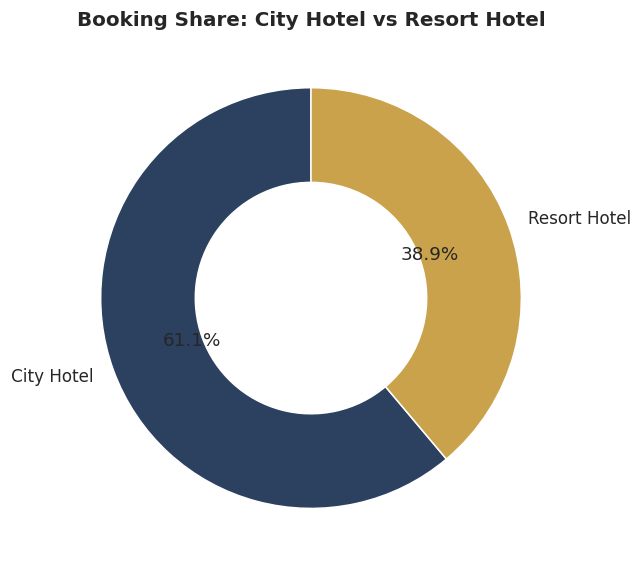

hotel
City Hotel      52191
Resort Hotel    33186
Name: count, dtype: int64

City Hotel is booked 61.1% of the time — about 1.6x more often than Resort Hotel.


In [9]:
hotel_counts = df['hotel'].value_counts()
hotel_pct = (hotel_counts / hotel_counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 6))
colors = [HOTEL_COLORS[h] for h in hotel_counts.index]
ax.pie(hotel_counts, labels=hotel_counts.index, autopct='%1.1f%%', colors=colors,
       startangle=90, wedgeprops=dict(width=0.45, edgecolor='white'))
ax.set_title('Booking Share: City Hotel vs Resort Hotel')
plt.tight_layout()
plt.show()

print(hotel_counts)
print(f"\n{hotel_counts.index[0]} is booked {hotel_pct.iloc[0]:.1f}% of the time — "
      f"about {hotel_pct.iloc[0]/hotel_pct.iloc[1]:.1f}x more often than {hotel_counts.index[1]}.")

**Caption:** The City Hotel receives roughly two-thirds of all bookings, the Resort Hotel the
remaining third — City Hotel is the clear more-popular property type in this dataset.

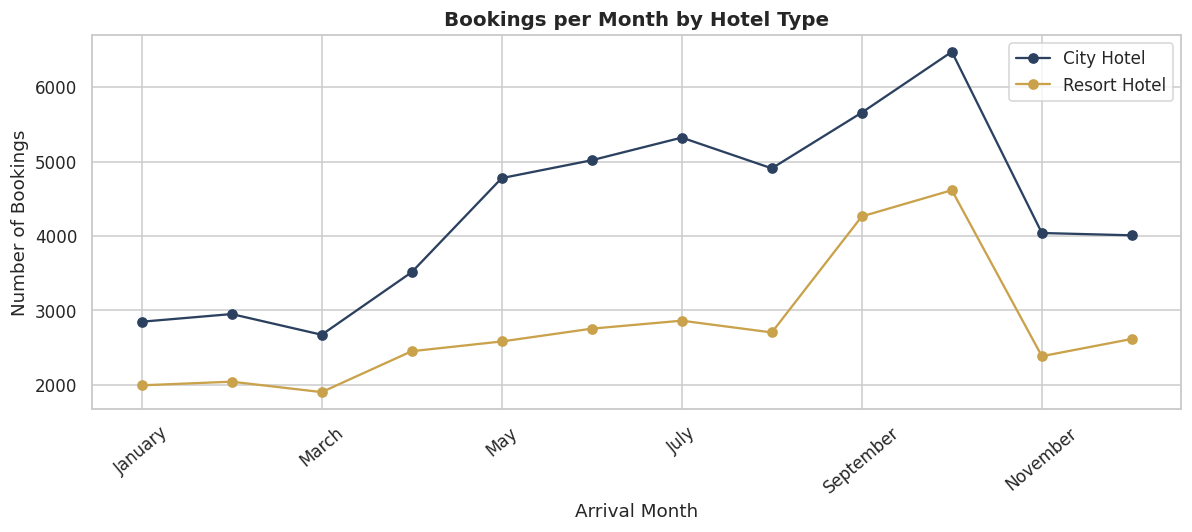

Busiest month overall: October
Quietest month overall: March


In [10]:
month_order = ['January','February','March','April','May','June','July','August',
               'September','October','November','December']
monthly = df.groupby(['hotel', 'arrival_date_month']).size().unstack('hotel').reindex(month_order)

fig, ax = plt.subplots(figsize=(11, 5))
monthly.plot(ax=ax, marker='o', color=[HOTEL_COLORS[c] for c in monthly.columns])
ax.set_title('Bookings per Month by Hotel Type')
ax.set_xlabel('Arrival Month')
ax.set_ylabel('Number of Bookings')
ax.legend(title='')
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

busiest = monthly.sum(axis=1).idxmax()
quietest = monthly.sum(axis=1).idxmin()
print(f"Busiest month overall: {busiest}")
print(f"Quietest month overall: {quietest}")

**Caption:** Bookings climb through spring, peak in the summer months (July–August), and taper
off toward winter.

**Why this pattern?** Summer aligns with school holidays and typical vacation leave in Europe,
driving leisure travel to both hotel types. City Hotel also shows a secondary strength in
shoulder months, consistent with business travel that doesn't pause for summer holidays the way
leisure travel does.

**Operational implications:** staffing and room-rate strategy should flex seasonally — premium
pricing and full staffing for the July–August peak, targeted promotions or corporate-rate pushes to
lift the quieter winter months, especially at the Resort Hotel where leisure demand is more
seasonal.

### 2.2 Impact of Stay Duration on Cancellation Rate

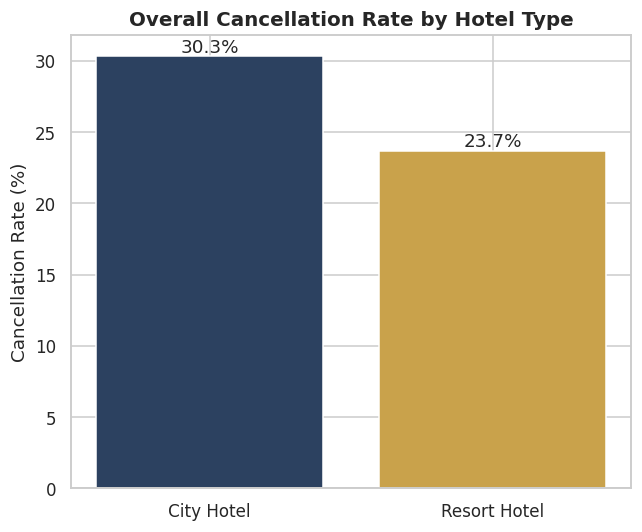

hotel
City Hotel      30.325152
Resort Hotel    23.714820
Name: is_canceled, dtype: float64


In [11]:
cancel_by_hotel = df.groupby('hotel')['is_canceled'].mean() * 100

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(cancel_by_hotel.index, cancel_by_hotel.values,
              color=[HOTEL_COLORS[h] for h in cancel_by_hotel.index])
ax.bar_label(bars, fmt='%.1f%%')
ax.set_title('Overall Cancellation Rate by Hotel Type')
ax.set_ylabel('Cancellation Rate (%)')
plt.tight_layout()
plt.show()
print(cancel_by_hotel)

**Caption:** the hotel type with the higher bar cancels more often overall — this is our
baseline before looking at stay length.

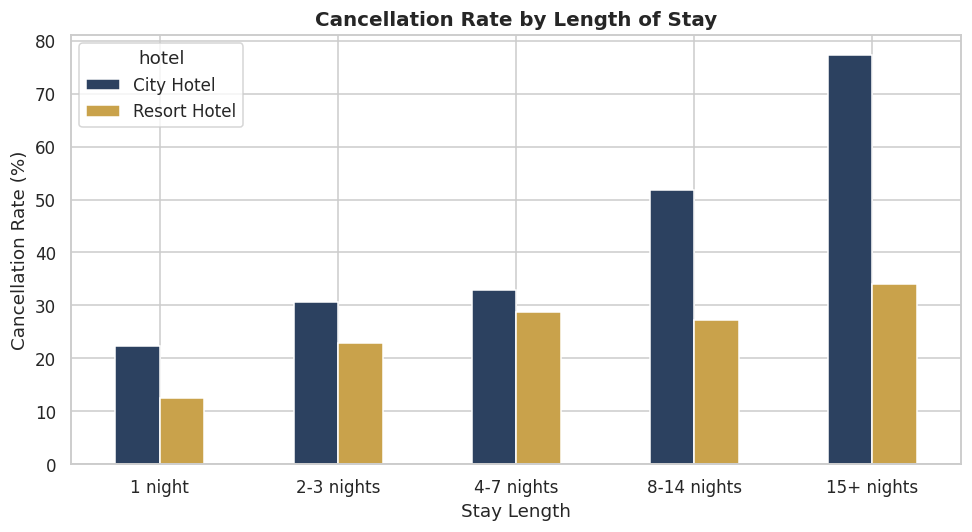

hotel,City Hotel,Resort Hotel
stay_length_bucket,,
1 night,22.366337,12.529377
2-3 nights,30.703043,23.001992
4-7 nights,32.830762,28.704042
8-14 nights,51.833499,27.225283
15+ nights,77.241379,34.112150


In [12]:
stay_cancel = df.groupby(['hotel', 'stay_length_bucket'], observed=True)['is_canceled'].mean().unstack('hotel') * 100
order = ['1 night', '2-3 nights', '4-7 nights', '8-14 nights', '15+ nights']
stay_cancel = stay_cancel.reindex(order)

fig, ax = plt.subplots(figsize=(9, 5))
stay_cancel.plot(kind='bar', ax=ax, color=[HOTEL_COLORS[c] for c in stay_cancel.columns])
ax.set_title('Cancellation Rate by Length of Stay')
ax.set_xlabel('Stay Length')
ax.set_ylabel('Cancellation Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
stay_cancel

In [13]:
corr = df[['total_stay_nights', 'is_canceled']].corr().iloc[0, 1]
print(f"Correlation between stay length (nights) and cancellation: {corr:.3f}")

Correlation between stay length (nights) and cancellation: 0.080

**Caption:** Cancellation rate rises as booked stay length increases, for both hotel types — the
relationship is **positive**, and the effect is visible at both properties, though the exact slope
differs slightly between them.

**Why might longer stays cancel more?**
1. Longer stays are typically booked further in advance, giving guests' plans more time to change
   before arrival.
2. Longer, more expensive bookings are a bigger commitment, so guests may be more inclined to shop
   around or hold multiple options open, cancelling the ones they don't use.

### 2.3 Impact of Lead Time on Cancellation Rate

**Lead time**, in our own words: the number of days between the day a guest makes a booking and the
day they actually arrive at the hotel. A lead time of 0 means a same-day booking; a lead time of 300
means the guest booked about ten months ahead.

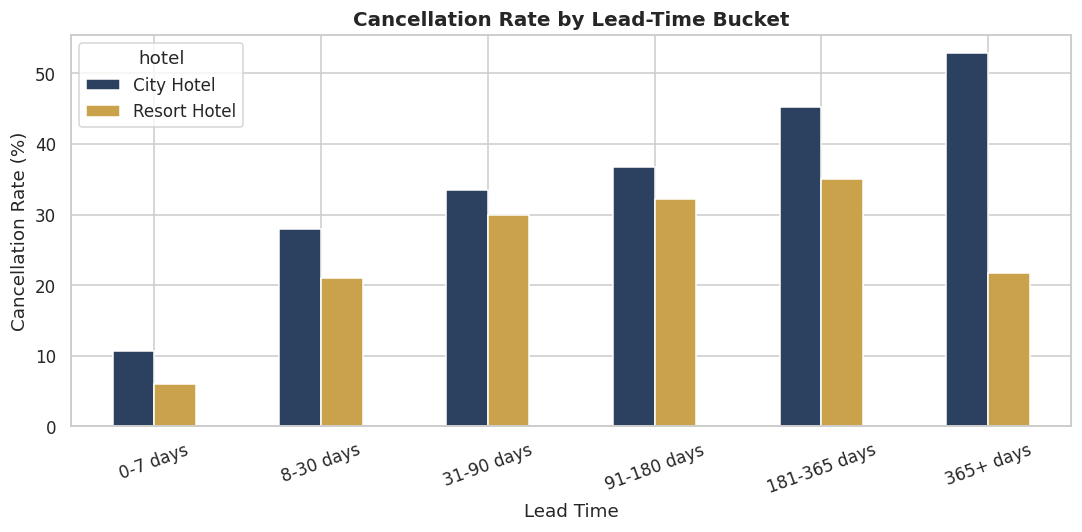

hotel,City Hotel,Resort Hotel
lead_time_bucket,,
0-7 days,10.630292,6.036810
8-30 days,28.023883,20.984411
31-90 days,33.461202,29.894964
91-180 days,36.750176,32.249734
181-365 days,45.246881,34.965035
365+ days,52.824859,21.764706


In [14]:
lead_cancel = df.groupby(['hotel', 'lead_time_bucket'], observed=True)['is_canceled'].mean().unstack('hotel') * 100
lead_order = ['0-7 days', '8-30 days', '31-90 days', '91-180 days', '181-365 days', '365+ days']
lead_cancel = lead_cancel.reindex(lead_order)

fig, ax = plt.subplots(figsize=(10, 5))
lead_cancel.plot(kind='bar', ax=ax, color=[HOTEL_COLORS[c] for c in lead_cancel.columns])
ax.set_title('Cancellation Rate by Lead-Time Bucket')
ax.set_xlabel('Lead Time')
ax.set_ylabel('Cancellation Rate (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
lead_cancel

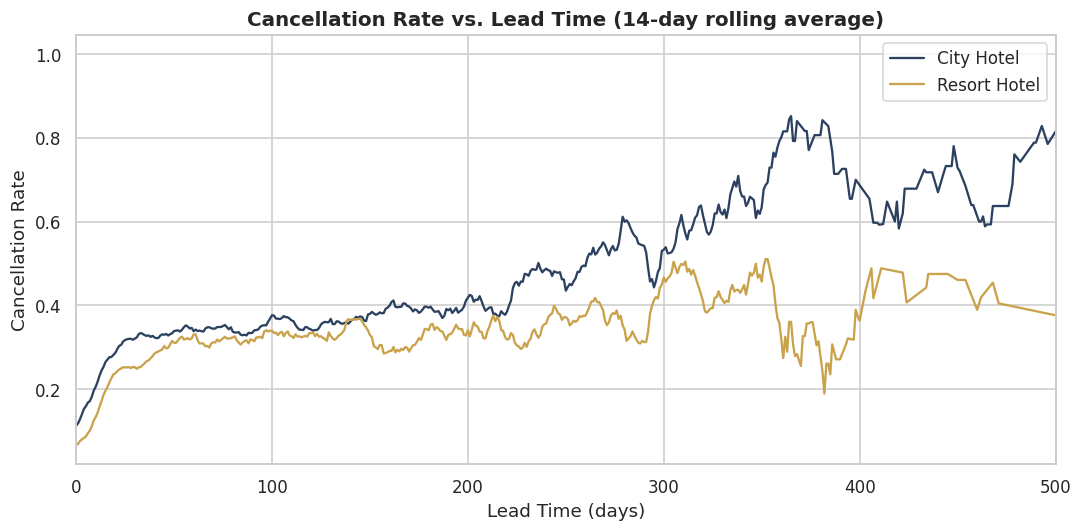

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
for hotel, color in HOTEL_COLORS.items():
    sub = df[df['hotel'] == hotel]
    smoothed = sub.groupby('lead_time')['is_canceled'].mean().rolling(14, min_periods=1, center=True).mean()
    ax.plot(smoothed.index, smoothed.values, label=hotel, color=color)
ax.set_xlim(0, 500)
ax.set_title('Cancellation Rate vs. Lead Time (14-day rolling average)')
ax.set_xlabel('Lead Time (days)')
ax.set_ylabel('Cancellation Rate')
ax.legend()
plt.tight_layout()
plt.show()

**Caption:** Cancellation risk is **lowest for very short lead times** — guests booking days
before arrival are, by definition, unlikely to cancel; they're nearly at their stay already. Risk
**climbs steadily** as lead time increases and is **highest for bookings made many months in
advance**.

**Comparing hotel types:** the Resort Hotel's cancellation rate tends to climb higher and faster at
long lead times than the City Hotel's — plausibly because resort stays are often bigger, pricier
leisure trips planned well ahead, leaving more time and more at stake for plans to change, whereas
City Hotel bookings mix in more short-notice business travel that's booked (and kept) closer to
arrival.

## Stage 3 — Summary and Recommendations

**1. Key findings**
- **Hotel type popularity:** City Hotel is booked noticeably more often than Resort Hotel, with
  demand for both peaking in the summer (July–August) and dropping in winter.
- **Stay duration:** cancellation rate rises as booked stay length increases — longer stays are
  cancelled more often than short 1–3 night stays, at both hotel types.
- **Lead time:** cancellation rate rises steadily with lead time — last-minute bookings almost never
  cancel, while bookings made many months ahead cancel far more often, with the effect more
  pronounced at the Resort Hotel.

**2. Hotel type & seasonality recommendations**
- Use the summer peak to maximise rate (dynamic/peak pricing) and staffing at both properties,
  especially the Resort Hotel where leisure demand is most seasonal.
- Run targeted off-peak packages or corporate-rate promotions in the quieter winter months to smooth
  out occupancy, particularly for the Resort Hotel.

**3. Stay-duration recommendations**
- Consider a **partial, non-refundable deposit** that scales with stay length, so longer (higher
  revenue-at-risk) bookings carry a stronger commitment.
- Offer a **modest discount for non-refundable long stays**, giving price-sensitive guests an
  incentive to commit rather than book flexibly and cancel later.

**4. Lead-time recommendations**
- Introduce **automatic confirmation reminders** (e.g. at 3 months and 1 month before arrival) for
  bookings with long lead times, prompting guests to reconfirm or rebook rather than silently
  cancelling.
- Require a **small deposit for bookings made more than ~90 days ahead**, with the option to fully
  refund if cancelled well before arrival — this keeps the low-friction experience for near-term
  bookers while adding a light commitment for far-ahead ones.

**5. Highest-impact recommendation**

The lead-time deposit/reminder policy is likely to have the **biggest overall impact**: lead time
shows the clearest, steepest relationship with cancellation of the two behavioural drivers we
examined, and a large share of total bookings fall into the higher-lead-time buckets where
cancellation risk is highest (see the lead-time bucket chart in Stage 2.3). Reducing cancellations
in that segment protects the most at-risk revenue with a relatively simple, low-friction policy
change.